#  Chest X-Ray Pneumonia Detection with CNN & Grad-CAM




In [7]:
# 1. Verify GPU Acceleration
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU: {torch.cuda.get_device_name(0)}")
    !nvidia-smi
else:
    print("Warning: Running on CPU. For faster training, go to Runtime -> Change runtime type -> T4 GPU.")


PyTorch Version: 2.14.1+cu130
CUDA Available: True
Active GPU: Tesla T4
Wed Nov 25 08:11:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |

In [8]:
# 2. Install Required Dependencies
!pip install -q kagglehub scikit-learn matplotlib pillow tqdm


In [9]:
# 3. Download and arrange dataset
import os
import shutil
from pathlib import Path
import kagglehub

print("[+] Downloading Chest X-Ray Pneumonia Dataset from Kaggle...")
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print(f"[+] Download complete: {path}")

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

source_chest_xray = Path(path) / "chest_xray"
if not source_chest_xray.exists():
    source_chest_xray = Path(path)

for split in ["train", "val", "test"]:
    src = source_chest_xray / split
    dst = data_dir / split
    if src.exists() and not dst.exists():
        print(f"  Organizing {split} split...")
        shutil.copytree(src, dst)

print("\n[+] Dataset structure summary:")
for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        p = data_dir / split / cls
        count = len(list(p.glob("*.*"))) if p.exists() else 0
        print(f"   {split}/{cls}: {count} images")


[+] Downloading Chest X-Ray Pneumonia Dataset from Kaggle...


100%|██████████| 2.29G/2.29G [00:21<00:00, 114MB/s]

Extracting files...


[+] Download complete: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2
  Organizing train split...
  Organizing val split...
  Organizing test split...

[+] Dataset structure summary:
   train/NORMAL: 1341 images
   train/PNEUMONIA: 3875 images
   val/NORMAL: 8 images
   val/PNEUMONIA: 8 images
   test/NORMAL: 234 images
   test/PNEUMONIA: 390 images


In [10]:
# 4. Neural Network Model Architectures
import torch
import torch.nn as nn
import torchvision.models as models


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, dropout_rate: float = 0.2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.1, inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(dropout_rate)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(x)


class PneumoniaCNN(nn.Module):
    def __init__(self, in_channels: int = 3, dropout_rate: float = 0.25):
        super().__init__()
        self.block1 = ConvBlock(in_channels, 32, dropout_rate=0.1)
        self.block2 = ConvBlock(32, 64, dropout_rate=0.2)
        self.block3 = ConvBlock(64, 128, dropout_rate=dropout_rate)
        self.block4 = ConvBlock(128, 256, dropout_rate=0.3)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.global_pool(x)
        return self.classifier(x)

    def get_last_conv_layer(self) -> nn.Module:
        return self.block4.conv[3]


class PneumoniaTransferNet(nn.Module):
    def __init__(self, pretrained: bool = True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        self.resnet = models.resnet18(weights=weights)
        in_features = self.resnet.fc.in_features
        self.resnet.fc = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.resnet(x)

    def get_last_conv_layer(self) -> nn.Module:
        return self.resnet.layer4[-1].conv2


def build_model(model_type: str = "resnet", pretrained: bool = True) -> nn.Module:
    if model_type.lower() == "custom":
        return PneumoniaCNN()
    else:
        return PneumoniaTransferNet(pretrained=pretrained)

print("[+] Model architectures defined successfully.")


[+] Model architectures defined successfully.


In [11]:
# 5. Dataset Loader & Augmentations
from typing import Dict, List, Tuple
from PIL import Image
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
import random

IMAGE_NET_MEAN = [0.485, 0.456, 0.406]
IMAGE_NET_STD = [0.229, 0.224, 0.225]


def get_transforms(img_size: int = 224):
    train_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomRotation(degrees=10),
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGE_NET_MEAN, std=IMAGE_NET_STD),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGE_NET_MEAN, std=IMAGE_NET_STD),
    ])
    return {"train": train_tf, "val": eval_tf, "test": eval_tf}


class ChestXRayDataset(Dataset):
    CLASS_TO_IDX = {"NORMAL": 0, "PNEUMONIA": 1}

    def __init__(self, samples: List[Tuple[str, int]], transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32)


def scan_directory(split_dir: str):
    samples = []
    path = Path(split_dir)
    if not path.exists():
        return samples
    for class_name, label_idx in ChestXRayDataset.CLASS_TO_IDX.items():
        folder = path / class_name
        if not folder.exists():
            for d in path.iterdir():
                if d.is_dir() and d.name.upper() == class_name:
                    folder = d
                    break
        if folder.exists():
            for f in folder.glob("*"):
                if f.suffix.lower() in [".jpeg", ".jpg", ".png"]:
                    samples.append((str(f), label_idx))
    return samples


def get_data_loaders(data_dir: str = "data", batch_size: int = 32, img_size: int = 224):
    transforms_dict = get_transforms(img_size)
    splits = ["train", "val", "test"]
    samples_dict = {s: scan_directory(os.path.join(data_dir, s)) for s in splits}

    # If official val split is too small (e.g. 16 images), transfer 10% from train for stable evaluation
    if len(samples_dict["val"]) < 30 and len(samples_dict["train"]) > 100:
        random.seed(42)
        random.shuffle(samples_dict["train"])
        transfer_count = int(0.10 * len(samples_dict["train"]))
        samples_dict["val"].extend(samples_dict["train"][:transfer_count])
        samples_dict["train"] = samples_dict["train"][transfer_count:]

    dataloaders = {}
    for s in splits:
        dataset = ChestXRayDataset(samples_dict[s], transform=transforms_dict[s])
        dataloaders[s] = DataLoader(
            dataset, batch_size=batch_size, shuffle=(s == "train"),
            num_workers=2, pin_memory=torch.cuda.is_available()
        )

    # Class balance weight
    pos_count = sum(1 for _, l in samples_dict["train"] if l == 1)
    neg_count = sum(1 for _, l in samples_dict["train"] if l == 0)
    pos_weight = float(neg_count) / max(float(pos_count), 1.0)

    print(f"[+] Train count: {len(samples_dict['train'])}, Val count: {len(samples_dict['val'])}, Test count: {len(samples_dict['test'])}")
    print(f"[+] Computed pos_weight: {pos_weight:.3f}")
    return dataloaders, pos_weight

print("[+] Dataset pipeline ready.")


[+] Dataset pipeline ready.


In [12]:
# 6. Training Routine
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score, confusion_matrix
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm import tqdm


def calculate_metrics(y_true, y_pred_probs, threshold=0.5):
    y_pred = (y_pred_probs >= threshold).astype(int)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    sens = recall_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    spec = float(tn) / float(tn + fp) if (tn + fp) > 0 else 0.0
    try:
        auc = roc_auc_score(y_true, y_pred_probs)
    except ValueError:
        auc = 0.5
    return {"accuracy": acc, "sensitivity": sens, "specificity": spec, "f1": f1, "auc": auc}


def train_model(model_type="resnet", epochs=8, batch_size=32, lr=1e-4):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[+] Training on device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

    dataloaders, pos_weight = get_data_loaders("data", batch_size=batch_size)
    model = build_model(model_type=model_type, pretrained=True).to(device)

    weight_tensor = torch.tensor([pos_weight], dtype=torch.float32, device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=weight_tensor)
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    best_f1 = -1.0
    best_weights_path = f"best_model_{model_type}.pth"
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": [], "val_sens": [], "val_spec": []}

    print("\nBeginning training loop...")
    for epoch in range(1, epochs + 1):
        # Training Phase
        model.train()
        train_loss = 0.0
        train_targets, train_preds = [], []

        for images, targets in tqdm(dataloaders["train"], desc=f"Epoch {epoch}/{epochs} [Train]", leave=False):
            images = images.to(device)
            targets = targets.unsqueeze(1).to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            probs = torch.sigmoid(logits).detach().cpu().numpy()
            train_preds.extend(probs.flatten())
            train_targets.extend(targets.cpu().numpy().flatten())

        t_loss = train_loss / len(dataloaders["train"].dataset)
        t_metrics = calculate_metrics(np.array(train_targets), np.array(train_preds))

        # Validation Phase
        model.eval()
        val_loss = 0.0
        val_targets, val_preds = [], []
        with torch.no_grad():
            for images, targets in dataloaders["val"]:
                images = images.to(device)
                targets = targets.unsqueeze(1).to(device)
                logits = model(images)
                loss = criterion(logits, targets)

                val_loss += loss.item() * images.size(0)
                probs = torch.sigmoid(logits).cpu().numpy()
                val_preds.extend(probs.flatten())
                val_targets.extend(targets.cpu().numpy().flatten())

        v_loss = val_loss / len(dataloaders["val"].dataset)
        v_metrics = calculate_metrics(np.array(val_targets), np.array(val_preds))
        scheduler.step(v_metrics["f1"])

        history["train_loss"].append(t_loss)
        history["val_loss"].append(v_loss)
        history["train_acc"].append(t_metrics["accuracy"])
        history["val_acc"].append(v_metrics["accuracy"])
        history["val_f1"].append(v_metrics["f1"])
        history["val_sens"].append(v_metrics["sensitivity"])
        history["val_spec"].append(v_metrics["specificity"])

        print(f"Epoch [{epoch:02d}/{epochs:02d}] | Train Loss: {t_loss:.4f} Acc: {t_metrics['accuracy']:.3f} | "
              f"Val Loss: {v_loss:.4f} Acc: {v_metrics['accuracy']:.3f} "
              f"Sens (Recall): {v_metrics['sensitivity']:.3f} Spec: {v_metrics['specificity']:.3f} F1: {v_metrics['f1']:.3f}")

        if v_metrics["f1"] > best_f1:
            best_f1 = v_metrics["f1"]
            torch.save({"model_state_dict": model.state_dict(), "model_type": model_type}, best_weights_path)
            print(f"  --> Saved new best checkpoint: {best_weights_path} (F1: {best_f1:.4f})")

    # Plot training curves
    plt.figure(figsize=(14, 4))
    plt.subplot(1, 3, 1)
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.title("BCE Loss")
    plt.legend()

    plt.subplot(1, 3, 2)
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["val_acc"], label="Val Acc")
    plt.plot(history["val_f1"], label="Val F1")
    plt.title("Accuracy & F1-Score")
    plt.legend()

    plt.subplot(1, 3, 3)
    plt.plot(history["val_sens"], label="Sensitivity", color="teal")
    plt.plot(history["val_spec"], label="Specificity", color="purple")
    plt.title("Clinical Sensitivity vs Specificity")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return model, best_weights_path


[+] Training on device: cuda (Tesla T4)
[+] Train count: 4695, Val count: 537, Test count: 624
[+] Computed pos_weight: 0.340
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]



Beginning training loop...


Epoch [01/08] | Train Loss: 0.1066 Acc: 0.929 | Val Loss: 0.0812 Acc: 0.920 Sens (Recall): 0.887 Spec: 1.000 F1: 0.940
  --> Saved new best checkpoint: best_model_resnet.pth (F1: 0.9399)


Epoch [02/08] | Train Loss: 0.0600 Acc: 0.967 | Val Loss: 0.0396 Acc: 0.978 Sens (Recall): 0.976 Spec: 0.981 F1: 0.984
  --> Saved new best checkpoint: best_model_resnet.pth (F1: 0.9840)


Epoch [03/08] | Train Loss: 0.0520 Acc: 0.970 | Val Loss: 0.0406 Acc: 0.963 Sens (Recall): 0.947 Spec: 1.000 F1: 0.973


Epoch [04/08] | Train Loss: 0.0437 Acc: 0.975 | Val Loss: 0.0329 Acc: 0.983 Sens (Recall): 0.982 Spec: 0.987 F1: 0.988
  --> Saved new best checkpoint: best_model_resnet.pth (F1: 0.9880)


Epoch [05/08] | Train Loss: 0.0338 Acc: 0.982 | Val Loss: 0.0336 Acc: 0.965 Sens (Recall): 0.953 Spec: 0.994 F1: 0.974


Epoch [06/08] | Train Loss: 0.0333 Acc: 0.981 | Val Loss: 0.0731 Acc: 0.972 Sens (Recall): 1.000 Spec: 0.905 F1: 0.981


Epoch [07/08] | Train Loss: 0.0309 Acc: 0.979 | Val Loss: 0.0221 Acc: 0.985 Sens (Recall): 0.982 Spec: 0.994 F1: 0.989
  --> Saved new best checkpoint: best_model_resnet.pth (F1: 0.9894)


Epoch [08/08] | Train Loss: 0.0274 Acc: 0.983 | Val Loss: 0.0365 Acc: 0.966 Sens (Recall): 0.953 Spec: 1.000 F1: 0.976


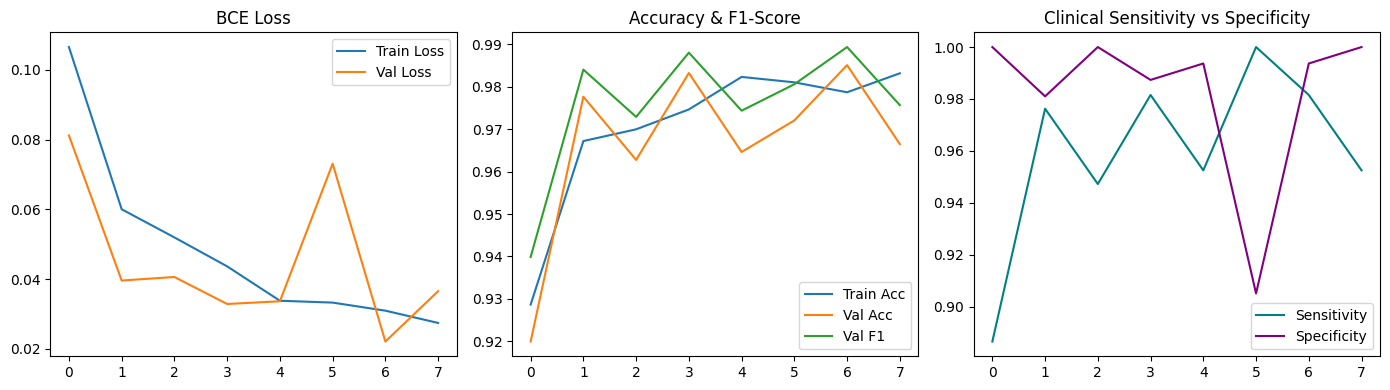

In [13]:
# 7. Start Training ResNet-18 Transfer Learning Model
# Typically takes ~3-4 minutes on Colab free T4 GPU for 6-8 epochs!
model, checkpoint_file = train_model(model_type="resnet", epochs=8, batch_size=32, lr=1e-4)


[+] Train count: 4695, Val count: 537, Test count: 624
[+] Computed pos_weight: 0.340
CLINICAL TEST SET EVALUATION REPORT
Accuracy:             88.14%
Sensitivity (Recall): 99.23%  (Catches pneumonia)
Specificity:          69.66%  (Identifies normal)
F1-Score:             0.9127
ROC-AUC:              0.9621


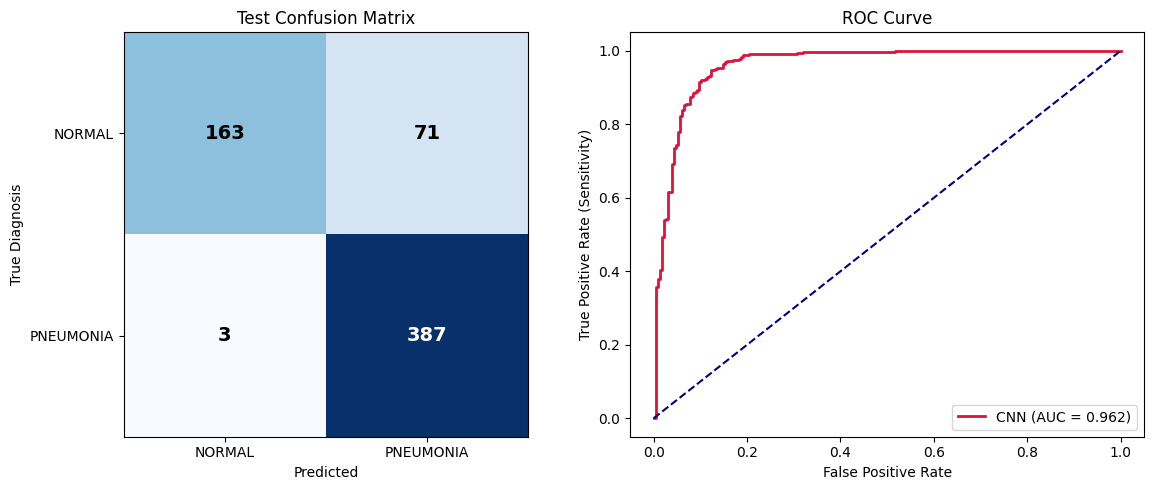

In [14]:
# 8. Evaluate on Independent Test Set
from sklearn.metrics import classification_report, roc_curve, roc_auc_score

def evaluate_test_set(checkpoint_path="best_model_resnet.pth", model_type="resnet"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = build_model(model_type=model_type, pretrained=False).to(device)

    chk = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(chk["model_state_dict"] if "model_state_dict" in chk else chk)
    model.eval()

    dataloaders, _ = get_data_loaders("data", batch_size=32)
    test_loader = dataloaders["test"]

    all_targets, all_probs = [], []
    with torch.no_grad():
        for images, targets in test_loader:
            images = images.to(device)
            logits = model(images)
            probs = torch.sigmoid(logits).cpu().numpy().flatten()
            all_probs.extend(probs)
            all_targets.extend(targets.numpy().flatten())

    y_true = np.array(all_targets, dtype=int)
    y_probs = np.array(all_probs, dtype=float)
    y_pred = (y_probs >= 0.5).astype(int)

    metrics = calculate_metrics(y_true, y_probs)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    print("=" * 55)
    print("CLINICAL TEST SET EVALUATION REPORT")
    print("=" * 55)
    print(f"Accuracy:             {metrics['accuracy'] * 100:.2f}%")
    print(f"Sensitivity (Recall): {metrics['sensitivity'] * 100:.2f}%  (Catches pneumonia)")
    print(f"Specificity:          {metrics['specificity'] * 100:.2f}%  (Identifies normal)")
    print(f"F1-Score:             {metrics['f1']:.4f}")
    print(f"ROC-AUC:              {metrics['auc']:.4f}")
    print("=" * 55)

    # Plot Confusion Matrix & ROC Curve
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    im = axes[0].imshow(cm, cmap=plt.cm.Blues)
    axes[0].set_xticks([0, 1])
    axes[0].set_yticks([0, 1])
    axes[0].set_xticklabels(["NORMAL", "PNEUMONIA"])
    axes[0].set_yticklabels(["NORMAL", "PNEUMONIA"])
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("True Diagnosis")
    axes[0].set_title("Test Confusion Matrix")

    for i in range(2):
        for j in range(2):
            axes[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=14, fontweight="bold")

    fpr, tpr, _ = roc_curve(y_true, y_probs)
    axes[1].plot(fpr, tpr, color="crimson", lw=2, label=f"CNN (AUC = {metrics['auc']:.3f})")
    axes[1].plot([0, 1], [0, 1], color="navy", linestyle="--")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate (Sensitivity)")
    axes[1].set_title("ROC Curve")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

evaluate_test_set("best_model_resnet.pth", model_type="resnet")


In [15]:
# 9. Grad-CAM Class & Overlay Functions
import matplotlib.cm as cm

class GradCAM:
    def __init__(self, model: nn.Module, target_layer: nn.Module = None):
        self.model = model
        self.model.eval()
        self.target_layer = target_layer if target_layer else model.get_last_conv_layer()
        self.gradients = None
        self.activations = None
        self.hook_handles = []
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()
        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.hook_handles.append(self.target_layer.register_forward_hook(forward_hook))
        self.hook_handles.append(self.target_layer.register_full_backward_hook(backward_hook))

    def generate_heatmap(self, input_tensor: torch.Tensor):
        self.model.zero_grad()
        output = self.model(input_tensor)
        target_score = output[0, 0]
        target_score.backward(retain_graph=True)

        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations[0]
        for i in range(len(pooled_gradients)):
            activations[i, :, :] *= pooled_gradients[i]

        heatmap = torch.mean(activations, dim=0).cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        max_val = np.max(heatmap)
        return heatmap / max_val if max_val > 0 else np.zeros_like(heatmap)

    def overlay(self, pil_image: Image.Image, heatmap: np.ndarray, alpha: float = 0.45):
        w, h = pil_image.size
        heatmap_resized = Image.fromarray(np.uint8(255 * heatmap)).resize((w, h), Image.Resampling.BILINEAR)
        heatmap_arr = np.array(heatmap_resized) / 255.0

        try:
            import matplotlib
            cmap = matplotlib.colormaps["jet"]
        except:
            cmap = cm.get_cmap("jet")

        colored_heatmap = np.uint8(255 * cmap(heatmap_arr)[:, :, :3])
        orig_arr = np.array(pil_image.convert("RGB"), dtype=np.float32)
        blended = (1.0 - alpha) * orig_arr + alpha * colored_heatmap.astype(np.float32)
        return Image.fromarray(np.clip(blended, 0, 255).astype(np.uint8))

    def remove_hooks(self):
        for h in self.hook_handles:
            h.remove()
        self.hook_handles = []

print("[+] Grad-CAM engine initialized.")


[+] Grad-CAM engine initialized.


Testing on sample radiograph: data/test/PNEUMONIA/person139_bacteria_666.jpeg


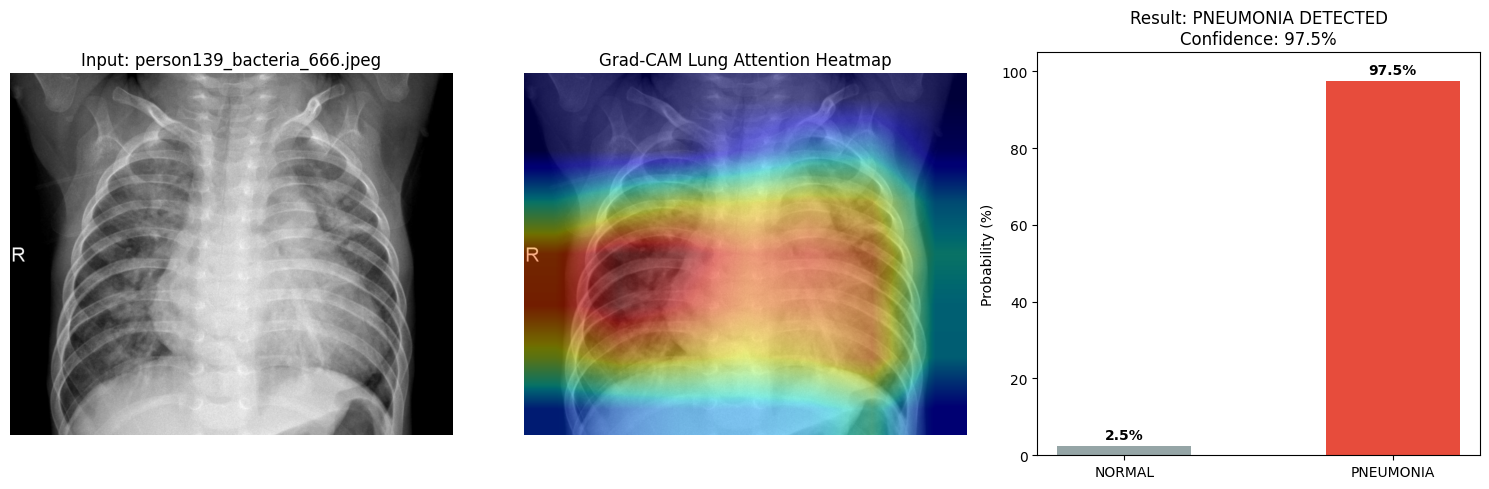


[!] To upload your own chest X-ray image, run:
uploaded = files.upload()
for filename, content in uploaded.items():
    diagnose_image(content, model)


In [16]:
# 10. Interactive Diagnostic Report Generator
from google.colab import files
from pathlib import Path
import io
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as transforms

def diagnose_image(image_input, model, checkpoint_path="best_model_resnet.pth"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    if isinstance(image_input, (str, Path)):
        raw_img = Image.open(image_input).convert("RGB")
        filename = Path(image_input).name
    else:
        raw_img = Image.open(io.BytesIO(image_input)).convert("RGB")
        filename = "Uploaded_Xray.jpg"

    tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGE_NET_MEAN, std=IMAGE_NET_STD)
    ])
    tensor = tf(raw_img).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        logit = model(tensor)
        pneumonia_prob = torch.sigmoid(logit).item()
        normal_prob = 1.0 - pneumonia_prob

    diagnosis = "PNEUMONIA DETECTED" if pneumonia_prob >= 0.5 else "NORMAL (NO PNEUMONIA)"
    confidence = pneumonia_prob if pneumonia_prob >= 0.5 else normal_prob

    # Grad-CAM
    cam = GradCAM(model)
    heatmap = cam.generate_heatmap(tensor)
    overlay_img = cam.overlay(raw_img, heatmap, alpha=0.45)
    cam.remove_hooks()

    # Visual Report
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(raw_img, cmap="gray")
    axes[0].set_title(f"Input: {filename}")
    axes[0].axis("off")

    axes[1].imshow(overlay_img)
    axes[1].set_title("Grad-CAM Lung Attention Heatmap")
    axes[1].axis("off")

    categories = ["NORMAL", "PNEUMONIA"]
    probs = [normal_prob * 100, pneumonia_prob * 100]
    colors = ["#2ecc71" if normal_prob >= 0.5 else "#95a5a6", "#e74c3c" if pneumonia_prob >= 0.5 else "#95a5a6"]
    bars = axes[2].bar(categories, probs, color=colors, width=0.5)
    axes[2].set_ylim(0, 105)
    axes[2].set_ylabel("Probability (%)")
    axes[2].set_title(f"Result: {diagnosis}\nConfidence: {confidence*100:.1f}%")

    for bar in bars:
        h = bar.get_height()
        axes[2].annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width()/2, h),
                         xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

    plt.tight_layout()
    plt.show()

# Example test on an actual test radiograph
test_dir = Path("data/test/PNEUMONIA")
test_images = [f for f in test_dir.rglob("*") if f.is_file() and f.suffix.lower() in [".jpeg", ".jpg", ".png"]]

if len(test_images) > 0:
    test_pneumonia_sample = test_images[0]
    print(f"Testing on sample radiograph: {test_pneumonia_sample}")
    diagnose_image(test_pneumonia_sample, model)
else:
    print(f"[!] Warning: No images found inside {test_dir} or subdirectories. Skip auto-run sample evaluation.")

print("\n[!] To upload your own chest X-ray image, run:")
print("uploaded = files.upload()")
print("for filename, content in uploaded.items():")
print("    diagnose_image(content, model)")

[+] Successfully loaded model checkpoint from 'best_model_resnet.pth'


Saving IM-0001-0001.jpeg to IM-0001-0001.jpeg


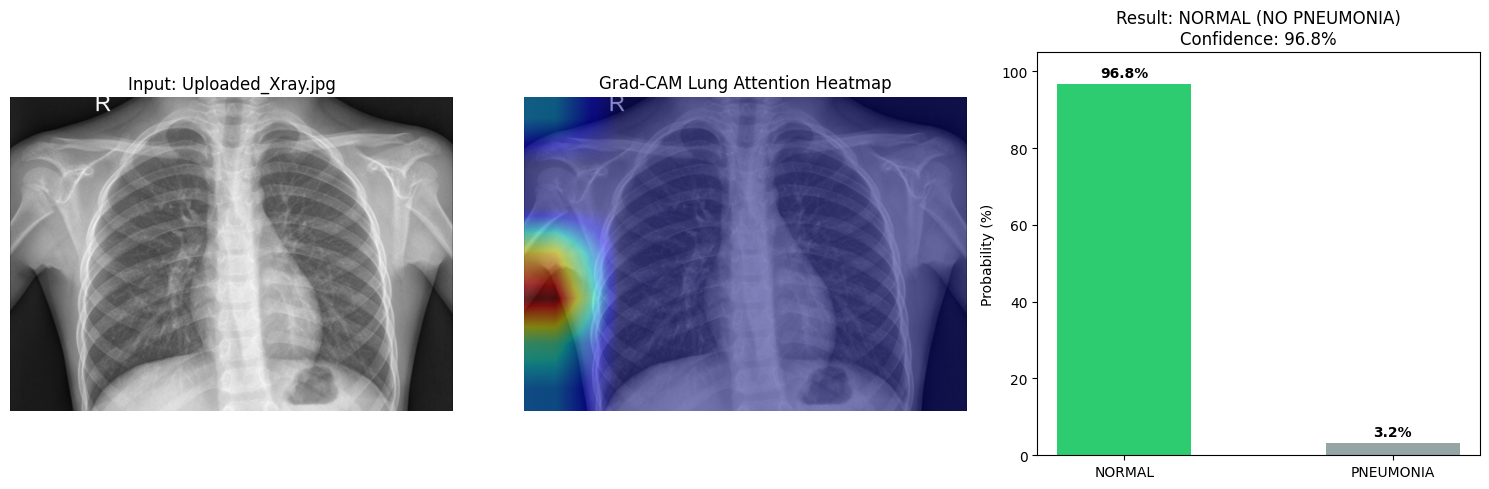

In [20]:
from google.colab import files
import torch

# Safely load the model from the saved checkpoint
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "best_model_resnet.pth"

try:
    # Re-build and load model structure and weights
    eval_model = build_model(model_type="resnet", pretrained=False).to(device)
    checkpoint = torch.load(checkpoint_path, map_location=device)
    eval_model.load_state_dict(checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint)
    eval_model.eval()

    print(f"[+] Successfully loaded model checkpoint from '{checkpoint_path}'")

    # Handle files
    uploaded = files.upload()
    for filename, content in uploaded.items():
        diagnose_image(content, eval_model)
except FileNotFoundError:
    print(f"[!] Error: Checkpoint '{checkpoint_path}' not found. Please ensure you have trained the model (Section 7) first.")
except NameError as e:
    print(f"[!] NameError: {e}. Make sure you have executed Section 4 (to define 'build_model') and Section 10.")